# Módulo 2: Extracción de Características y Descriptores (Parte II)
## Trabajo Práctico 2: Descriptores Clásicos de Texturas y Clasificación de Prendas

**Cátedra:** Visión por Computadora — 5to Año
**FICH-UNL (Santa Fe, Argentina)**


### Objetivos del Trabajo Práctico:
1. Comprender la naturaleza espacial, estadística y espectral de las texturas en imágenes.
2. Implementar desde las bases y evaluar descriptores clásicos: LBP, GLCM y HOG.
3. Diseñar bancos de filtros de Gabor y analizar la descomposición multirresolución mediante la Transformada Wavelet.
4. Desarrollar un sistema integrador de clasificación para reconocer texturas de prendas de vestir utilizando descriptores fusionados.

---

### Celda de Configuración Inicial (Obligatoria)
Ejecutá esta celda para cargar las dependencias esenciales de procesamiento de imágenes, herramientas de machine learning, visualización e interactividad.

In [9]:
import cv2 as cv
import numpy as np
import matplotlib.pyplot as plt
from scipy import ndimage
from ipywidgets import interact, IntSlider, FloatSlider, Dropdown, Checkbox
from skimage.feature import local_binary_pattern, graycomatrix, graycoprops, hog
import warnings
warnings.filterwarnings('ignore')

In [10]:
# Función auxiliar estándar para mostrar imágenes y mapas de texturas lado a lado
def mostrar_resultado(original, procesada, titulo_orig="Original", titulo_proc="Textura/Descriptor", cmap_orig="gray", cmap_proc="gray"):
    fig, ax = plt.subplots(1, 2, figsize=(12, 5))
    ax.imshow(original, cmap=cmap_orig)
    ax.set_title(titulo_orig)
    ax.axis('off')

    im = ax[1].imshow(procesada, cmap=cmap_proc)
    ax[1].set_title(titulo_proc)
    ax[1].axis('off')
    if cmap_proc != "gray":
        plt.colorbar(im, ax=ax[1], fraction=0.046, pad=0.04)
    plt.tight_layout()
    plt.show()

print("✅ Entorno configurado correctamente.")
print("⚠️ Recuerden subir los assets requeridos: 'lana.png', 'algodon.png', 'denim.png' y las carpetas de prendas antes de iniciar.")

✅ Entorno configurado correctamente.
⚠️ Recuerden subir los assets requeridos: 'lana.png', 'algodon.png', 'denim.png' y las carpetas de prendas antes de iniciar.


---
## Ejercicio 1: Local Binary Patterns (LBP) de Textura Local

### Objetivo:
Implementar el operador básico de Patrones Binarios Locales (LBP) de 3x3 píxeles desde sus bases algorítmicas, analizar su robustez a variaciones de iluminación monótonas y mapear su distribución en histogramas de textura.

In [11]:
def lbp_manual(imagen_gris):
    """
    Implementación manual paso a paso de LBP clásico de 3x3 en conectividad-8.
    """
    filas, columnas = imagen_gris.shape
    # Crear salida con margen simple
    lbp_img = np.zeros((filas-2, columnas-2), dtype=np.uint8) #le saca fila arriba fila abajo columna primera y ultima

    # Recorrer píxeles internos
    for r in range(1, filas - 1): #padding
        for c in range(1, columnas - 1): #padding
            gc = imagen_gris[r, c] # Píxel central

            # Obtener vecinos en sentido horario desde el norte (p2 a p9)
            p2 = imagen_gris[r-1, c] #arriba
            p3 = imagen_gris[r-1, c+1]
            p4 = imagen_gris[r, c+1]
            p5 = imagen_gris[r+1, c+1]
            p6 = imagen_gris[r+1, c]
            p7 = imagen_gris[r+1, c-1]
            p8 = imagen_gris[r, c-1]
            p9 = imagen_gris[r-1, c-1]

            vecinos = [p2, p3, p4, p5, p6, p7, p8, p9]
            bits = []

            for v in vecinos:
                if v >= gc:
                    bits.append(1)
                else:
                    bits.append(0)

            #conv

            valor_lbp = 0
            for i, bit in enumerate(bits):
                valor_lbp += bit * (2 ** i)


            # ---------------------- #

            # ---------------------- #

            lbp_img[r-1, c-1] = valor_lbp #para guardar en la pocision correcta hay que restar uno porque nos falta una columna

    return lbp_img



💡 **Reflexión Guía - Ejercicio 1:**
1. Al interactuar con el contraste y el brillo de la lana, compará los histogramas de LBP del panel inferior. ¿Sufren variaciones en su distribución probabilística? Justificá matemáticamente a nivel de desigualdad local por qué LBP es inmune ante transformaciones de iluminación de tipo monótonas crecentes.
2. ¿Cuál es el problema de usar el LBP clásico de 3x3 de 8 vecinos frente al ruido de alta frecuencia? ¿Cómo ayuda el concepto de "LBP Uniformes" a mitigar este desvío?

**Enlaces y Lecturas Sugeridas:**
- [scikit-image LBP Documentation](https://scikit-image.org/docs/stable/api/skimage.feature.html#skimage.feature.local_binary_pattern)
- [Local Binary Patterns - Scholarpedia](http://www.scholarpedia.org/article/Local_Binary_Patterns)

**Parte 1**
Vamos a definir nuestras imagenes como $$I'(x,y) = \gamma I(x,y) + b$$ donde
- b es cambio de brillo
- \gamma es cambio de contraste

Si cambiamos gamma, si antes un vecino era mayor, despues sigue siendo mayor. Entonces LBP(I')=LBP(I)

In [ ]:
def explorar_lbp_iluminacion(brillo_offset, contraste_gamma):
    # Cargar textura de lana
    img = cv.imread('Imagenes/lana.jpg', cv.IMREAD_GRAYSCALE)

    if img is None:
        print("No se pudo cargar lana.jfif")
        return

    # Aplicar transformación de iluminación
    img_mod = np.clip(
        contraste_gamma * img.astype(float) + brillo_offset,
        0,
        255
    ).astype(np.uint8)

    # Calcular LBP
    lbp_orig = lbp_manual(img)
    lbp_mod = lbp_manual(img_mod)

    # Crear gráficos
    fig, ax = plt.subplots(2, 2, figsize=(8, 6))

    # Imagen original
    ax[0, 0].imshow(img, cmap='gray')
    ax[0, 0].set_title("Lana original")
    ax[0, 0].axis('off')

    # Imagen modificada
    ax[0, 1].imshow(img_mod, cmap='gray')
    ax[0, 1].set_title(
        f"Lana modificada\nBrillo: {brillo_offset} | Contraste: {contraste_gamma}"
    )
    ax[0, 1].axis('off')

    # Histograma original
    ax[1, 0].hist(
        lbp_orig.ravel(),
        bins=256,
        range=(0, 256),
        density=True
    )
    ax[1, 0].set_title("Histograma LBP original")
    ax[1, 0].set_xlabel("Código LBP")
    ax[1, 0].set_ylabel("Probabilidad")

    # Histograma modificado
    ax[1, 1].hist(
        lbp_mod.ravel(),
        bins=256,
        range=(0, 256),
        density=True
    )
    ax[1, 1].set_title("Histograma LBP modificado")
    ax[1, 1].set_xlabel("Código LBP")
    ax[1, 1].set_ylabel("Probabilidad")

    plt.tight_layout()
    plt.show()


interact(
    explorar_lbp_iluminacion,
    brillo_offset=IntSlider(
        min=-50,
        max=100,
        step=10,
        value=20
    ),
    contraste_gamma=FloatSlider(
        min=0.5,
        max=1.8,
        step=0.1,
        value=1.2
    )
)

interactive(children=(IntSlider(value=20, description='brillo_offset', min=-50, step=10), FloatSlider(value=1.…

<function __main__.explorar_lbp_iluminacion(brillo_offset, contraste_gamma)>

**Parte 2**
Vamos a probar meterle rudio

In [19]:
img = cv.imread('Imagenes/lana.jfif', cv.IMREAD_GRAYSCALE)
lbp_original = lbp_manual(img)

ruido = np.random.normal(0, 0.5, img.shape)

img_ruidosa = np.clip(
    img.astype(float) + ruido,
    0,
    255
).astype(np.uint8)

lbp_ruidosa = lbp_manual(img_ruidosa)

---
## Ejercicio 2: Matriz de Co-ocurrencia de Niveles de Gris (GLCM)

### Objetivo:
Implementar la lógica de acumulación espacial de la matriz de co-ocurrencia para un desplazamiento y dirección determinados, y derivar descriptores estadísticas de segundo orden de Haralick.

<class 'numpy.ndarray'>
(350, 586)


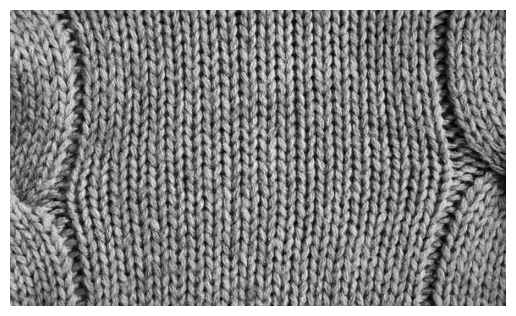

In [26]:
import cv2 as cv
import matplotlib.pyplot as plt

img = cv.imread('Imagenes/lana.jfif', cv.IMREAD_GRAYSCALE)

print(type(img))
print(img.shape)

plt.imshow(img, cmap='gray')
plt.axis('off')
plt.show()

In [ ]:
def glcm_manual_normalizada(imagen_gris, d, theta_grados, niveles_gris=4):
    """
    Construye la matriz GLCM para una imagen reducida a 'niveles_gris' cuantizados.
    Desplazamiento d, Ángulo theta en grados (0, 45, 90 o 135).

    Retorna
    -------
    glcm_norm : np.ndarray
        GLCM simétrica y normalizada.
    img_cuant : np.ndarray
        Imagen cuantizada a 'niveles_gris' niveles (para visualización).
    """
    # Cuantizar estirando el rango real [p_min, p_max] a [0, niveles_gris-1]
    p_min, p_max = imagen_gris.min(), imagen_gris.max()
    img_norm = (imagen_gris.astype(np.float32) - p_min) / (p_max - p_min + 1e-9)
    img_cuant = np.round(img_norm * (niveles_gris - 1)).astype(np.uint8)

    filas, columnas = img_cuant.shape
    glcm = np.zeros((niveles_gris, niveles_gris), dtype=float)

    # Definir el paso espacial de desplazamiento en coordenadas (dr, dc)
    if theta_grados == 0:
        dr, dc = 0, d
    elif theta_grados == 45:
        dr, dc = d, d
    elif theta_grados == 90:
        dr, dc = d, 0
    elif theta_grados == 135:
        dr, dc = d, -d
    else:
        raise ValueError("Ángulo no soportado. Use 0, 45, 90 o 135.")

    # Recorrer la imagen y llenar la GLCM
    for r in range(filas):
        for c in range(columnas):
            r2, c2 = r + dr, c + dc
            if 0 <= r2 < filas and 0 <= c2 < columnas:
                i = img_cuant[r, c]
                j = img_cuant[r2, c2]
                glcm[i, j] += 1

    # Simetrizar
    glcm_sim = glcm + glcm.T

    total = glcm_sim.sum()
    if total == 0:
        return np.zeros_like(glcm_sim), img_cuant

    glcm_norm = glcm_sim / total
    return glcm_norm, img_cuant


def calcular_metricas_haralick(glcm_p):
    """
    Calcula Contraste y Homogeneidad en base a la GLCM normalizada probabilística glcm_p.
    """
    niveles = glcm_p.shape[0]
    contraste = 0.0
    homogeneidad = 0.0

    for i in range(niveles):
        for j in range(niveles):
            contraste += glcm_p[i, j] * (i - j) ** 2
            homogeneidad += glcm_p[i, j] / (1 + (i - j) ** 2)

    return contraste, homogeneidad


def explorar_glcm(distancia, angulo):
    try:
        img = cv.imread('Imagenes/lana.jpg', cv.IMREAD_GRAYSCALE)
        if img is None:
            img = (np.sin(np.linspace(0, 15, 256))[:, None] * 127 + 128).astype(np.uint8)

        niveles = 8
        glcm, img_cuant = glcm_manual_normalizada(img, distancia, angulo, niveles_gris=niveles)
        cont, homo = calcular_metricas_haralick(glcm)

        # --- Plot triple: original | cuantizada | GLCM ---
        fig, ax = plt.subplots(1, 3, figsize=(16, 5))

        # 1) Original
        ax[0].imshow(img, cmap='gray')
        ax[0].set_title("Imagen original")
        ax[0].axis('off')

        # 2) Cuantizada (vmin/vmax fijos para ver los escalones discretos)
        im_c = ax[1].imshow(img_cuant, cmap='gray', vmin=0, vmax=niveles - 1)
        ax[1].set_title(f"Imagen cuantizada ({niveles} niveles)")
        ax[1].axis('off')
        plt.colorbar(im_c, ax=ax[1], fraction=0.046, pad=0.04)

        # 3) GLCM
        im_g = ax[2].imshow(glcm, cmap='hot', origin='upper')
        ax[2].set_title(
            f"GLCM (d={distancia}, θ={angulo}°)\n"
            f"Contraste: {cont:.4f} | Homogeneidad: {homo:.4f}"
        )
        ax[2].set_xlabel("Nivel de gris del vecino (j)")
        ax[2].set_ylabel("Nivel de gris central (i)")
        plt.colorbar(im_g, ax=ax[2], fraction=0.046, pad=0.04)

        plt.tight_layout()
        plt.show()

    except Exception as e:
        print("Error:", e)


interact(explorar_glcm,
         distancia=IntSlider(min=1, max=10, step=1, value=2),
         angulo=Dropdown(options=[0, 45, 90, 135], value=0))

interactive(children=(IntSlider(value=2, description='distancia', max=10, min=1), Dropdown(description='angulo…

<function __main__.explorar_glcm(distancia, angulo)>

💡 **Reflexión Guía - Ejercicio 2:**
1. Desplazá el ángulo de la co-ocurrencia entre `0` (horizontal) y `90` (vertical). ¿Qué le ocurre a la distribución de energía (celdas) en la matriz GLCM si la textura presenta un patrón de hilos marcadamente vertical? ¿Hacia dónde se desplaza la matriz y por qué?
2. Si la homogeneidad es muy alta, ¿cómo se posicionan probabilísticamente las celdas de la GLCM respecto a la diagonal principal? Explicá la relación física con la disimilitud textural.

**Enlaces y Lecturas Sugeridas:**
- [scikit-image GLCM Props API](https://scikit-image.org/docs/stable/api/skimage.feature.html#skimage.feature.graycoprops)
- [Haralick Texture Features Paper (1973)](https://ieeexplore.ieee.org/document/4309314)

Como se concentra en la diagonal, la imagen tiene bastante homogeneidad, los pixeles son adyacentes y hay homogeneidad

---
## Ejercicio 3: Histogram of Oriented Gradients (HOG) Geométrico

### Objetivo:
Estudiar la descomposición vectorial de HOG para describir siluetas y regularidades texturales locales mediante histogramas de orientación de gradientes discretizados por celdas.

In [23]:
def calcular_gradiente_hog(img):
    """
    Calcula la magnitud y dirección [0, 180] del gradiente usando Sobel.
    """

    Ix = cv.Sobel(img, cv.CV_64F, 1, 0, ksize=3)
    Iy = cv.Sobel(img, cv.CV_64F, 0, 1, ksize=3)

    magnitud = np.sqrt(Ix**2 + Iy**2)

    angulo = np.degrees(np.arctan2(Iy, Ix)) 
    angulo = angulo % 180 

    return magnitud, angulo

In [ ]:
def explorar_hog(pixels_por_celda, celdas_por_bloque, orientaciones): 
    try: 
        img = cv.imread('Imagenes/lana.jfif', cv.IMREAD_GRAYSCALE) 

        if img is None: 
            img = (np.sin(np.linspace(0, 30, 256))[:, None] * 127 + 128).astype(np.uint8) 
 
        # Extraer descriptores usando skimage
        features, hog_viz = hog(
            img, 
            orientations=orientaciones, 
            pixels_per_cell=(pixels_por_celda, pixels_por_celda), 
            cells_per_block=(celdas_por_bloque, celdas_por_bloque), 
            visualize=True
        ) 
 
        # Normalizar visualización de HOG para mayor contraste
        hog_viz_rescaled = np.clip(
            hog_viz * 20, 
            0, 
            255
        ).astype(np.uint8)

        # Mostrar resultado
        fig, ax = plt.subplots(1, 2, figsize=(12, 5))

        ax[0].imshow(img, cmap='gray')
        ax[0].set_title("Textura Lana")
        ax[0].axis('off')

        ax[1].imshow(hog_viz_rescaled, cmap='gray')
        ax[1].set_title(
            f"HOG (Celda: {pixels_por_celda}x{pixels_por_celda}, "
            f"Bins: {orientaciones})\n"
            f"Feature vector: {len(features)}D"
        )
        ax[1].axis('off')

        plt.tight_layout()
        plt.show()

    except Exception as e: 
        print("Error:", e) 
 
interact(
    explorar_hog, 
    pixels_por_celda=Dropdown(
        options=[4, 8, 16, 32], 
        value=16
    ), 
    celdas_por_bloque=Dropdown(
        options=[1, 2, 3], 
        value=2
    ), 
    orientaciones=IntSlider(
        min=4, 
        max=18, 
        step=1, 
        value=9
    )
)

#orientaciones es la cantidad de bins de direcciones que se tienen


interactive(children=(Dropdown(description='pixels_por_celda', index=2, options=(4, 8, 16, 32), value=16), Dro…

<function __main__.explorar_hog(pixels_por_celda, celdas_por_bloque, orientaciones)>

💡 **Reflexión Guía - Ejercicio 3:**
1. Variá las orientaciones (`bins`) entre `4` y `18`. ¿Cómo cambia la transformación de la dimensionalidad del vector descriptor de salida y cuál es el compromiso matemático entre resolución de orientación y sobreajuste o sobrecarga computacional?
2. ¿Por qué se implementa la normalización por bloques deslizantes superpuestos (e.g. bloques 2x2) en lugar de normalizar de forma aislada cada celda individualmente?

**Enlaces y Lecturas Sugeridas:**
- [scikit-image HOG Feature Extraction API](https://scikit-image.org/docs/stable/api/skimage.feature.html#skimage.feature.hog)
- [Dalal & Triggs Pedestrian Detection HOG Paper (2005)](https://ieeexplore.ieee.org/document/1467360)

---
## Ejercicio 4: Filtros de Gabor y Texturas Direccionales

### Objetivo:
Construir y aplicar núcleos analíticos de convolución de Gabor para capturar componentes espectrales orientados y frecuencias armónicas espaciales específicas.

In [47]:
def gabor_kernel_manual(theta, frecuencia, sigma_x, sigma_y):
    """
    Genera el núcleo real de Gabor en 2D.
    """
    # Crear coordenadas de grilla espacial del kernel [-15, 15]
    sz = 15
    y, x = np.mgrid[-sz:sz+1, -sz:sz+1]

    # Rotación de coordenadas según el ángulo theta
    theta_rad = np.deg2rad(theta)
    x_rot = x * np.cos(theta_rad) + y * np.sin(theta_rad) #seria x'
    y_rot = -x * np.sin(theta_rad) + y * np.cos(theta_rad) #seria y'

    #ecuacion

    gauss   = np.exp(-(x_rot**2 / (2 * sigma_x**2) + y_rot**2 / (2 * sigma_y**2))) #gauss rotado
    sinusoide = np.cos(2*np.pi*frecuencia*x_rot) #seno en un sentido?)

    kernel  = gauss * sinusoide
    # ---------------------- #

    return kernel


In [50]:
def explorar_gabor(theta, frecuencia, sigma, anisotropia):
    try:
        img = cv.imread('Imagenes/lana.jpg', cv.IMREAD_GRAYSCALE)
        if img is None:
            img = (np.sin(np.linspace(0, 10, 256))[:, None] * 127 + 128).astype(np.uint8)

        sigma_x = sigma
        sigma_y = sigma / anisotropia

        # Generar núcleo
        kernel = gabor_kernel_manual(theta, frecuencia, sigma_x, sigma_y)

        # Aplicar convolución espacial
        res = cv.filter2D(img, cv.CV_64F, kernel)
        res_mag = np.abs(res)

        # Energía media del mapa de respuesta
        energia_media = res_mag.mean()

        # Normalización solo para visualización
        res_norm = np.clip(res_mag * 255 / (np.max(res_mag) + 1e-6), 0, 255).astype(np.uint8)

        print(f"Energía media del mapa: {energia_media:.4f}")

        # Mostrar el kernel y la respuesta espacial
        fig, ax = plt.subplots(1, 3, figsize=(15, 5))
        ax[0].imshow(img, cmap='gray')
        ax[0].set_title("Muestra lana")
        ax[0].axis('off')

        # Visualización del kernel centrado
        ax[1].imshow(kernel, cmap='bwr', origin='lower')
        ax[1].set_title(f"Kernel Gabor Real (Theta: {theta}°)")
        ax[1].axis('off')

        ax[2].imshow(res_norm, cmap='plasma')
        ax[2].set_title(f"Mapa de Respuesta Textural\nEnergía media: {energia_media:.4f}")
        ax[2].axis('off')
        plt.tight_layout()
        plt.show()
    except Exception as e:
        print("Error:", e)


interact(explorar_gabor,
         theta=IntSlider(min=0, max=180, step=15, value=45),
         frecuencia=FloatSlider(min=0.05, max=0.6, step=0.05, value=0.15),
         sigma=FloatSlider(min=1.0, max=8.0, step=0.5, value=3.0),
         anisotropia=FloatSlider(min=0.5, max=3.0, step=0.5, value=1.0))

interactive(children=(IntSlider(value=45, description='theta', max=180, step=15), FloatSlider(value=0.15, desc…

<function __main__.explorar_gabor(theta, frecuencia, sigma, anisotropia)>

💡 **Reflexión Guía - Ejercicio 4:**
1. Observá la respuesta espacial al convolucionar variando `theta`. ¿Cómo cambia la magnitud del mapa de energía cuando el ángulo del filtro coincide exactamente con la dirección natural del patrón de fibras de la lana? ¿Qué relación geométrica se establece?
2. ¿Por qué el filtro de Gabor se describe como un modulador armónico localizado espacialmente por una Gaussiana? ¿Por qué no usamos simplemente transformaciones periódicas senoidales puras sin modular?

**Enlaces y Lecturas Sugeridas:**
- [OpenCV Gabor Filter Kernel (`cv.getGaborKernel`)](https://docs.opencv.org/4.x/d4/d86/group__imgproc__filter.html#gae84c6f25ab5037d0507d347aaf65957a)
- [Gabor Filter Theory on Wikipedia](https://en.wikipedia.org/wiki/Gabor_filter)

---
## Ejercicio 5: Transformada Wavelet y Descomposición Multirresolución (Opcional)

### Objetivo:
Estudiar la descomposición de texturas en componentes frecuenciales mediante la Transformada Wavelet Discreta 2D (DWT) de un nivel, aislando las subbandas de aproximación y detalle.

In [ ]:
def dwt_2d_haar_1nivel(imagen_gris):
    """
    Implementa la descomposición DWT 2D de un nivel usando la Wavelet de Haar.
    """
    # Asegurar que las dimensiones sean pares
    if imagen_gris.shape[0] % 2 != 0:
        imagen_gris = imagen_gris[:-1, :]
    if imagen_gris.shape[1] % 2 != 0:
        imagen_gris = imagen_gris[:, :-1]

    img = imagen_gris.astype(float)
    filas, columnas = img.shape

    # Filtros de Haar discretos: pasa-bajo h = [1, 1]/sqrt(2), pasa-alto g = [1, -1]/sqrt(2)
    # TODO: Implementar el filtrado y submuestreo de filas y columnas paso a paso de Mallat.
    # 1. Aplicar sumas y restas de vecinos de forma bidimensional (LL, LH, HL, HH)
    # LL = (A + B + C + D)/2, LH = (A - B + C - D)/2 ...
    # --- COMPLETAR AQUÍ --- #
    LL = np.zeros((filas//2, columnas//2))
    LH = np.zeros((filas//2, columnas//2))
    HL = np.zeros((filas//2, columnas//2))
    HH = np.zeros((filas//2, columnas//2))
    # ---------------------- #

    return LL, LH, HL, HH

def explorar_wavelets():
    try:
        # Cargar denim
        img = cv.imread('denim.png', cv.IMREAD_GRAYSCALE)
        if img is None:
            img = (np.sin(np.linspace(0, 30, 256))[:, None] * 127 + 128).astype(np.uint8)

        LL, LH, HL, HH = dwt_2d_haar_1nivel(img)

        # Graficar subbandas
        fig, ax = plt.subplots(2, 2, figsize=(10, 10))

        ax[0, 0].imshow(LL, cmap='gray')
        ax[0, 0].set_title("LL: Aproximación (Baja-Baja)")
        ax[0, 0].axis('off')

        ax[0, 1].imshow(np.abs(LH), cmap='plasma')
        ax[0, 1].set_title("LH: Detalle Horizontal (Baja-Alta)")
        ax[0, 1].axis('off')

        ax[1, 0].imshow(np.abs(HL), cmap='plasma')
        ax[1, 0].set_title("HL: Detalle Vertical (Alta-Baja)")
        ax[1, 0].axis('off')

        ax[1, 1].imshow(np.abs(HH), cmap='plasma')
        ax[1, 1].set_title("HH: Detalle Diagonal (Alta-Alta)")
        ax[1, 1].axis('off')

        plt.tight_layout()
        plt.show()
    except Exception as e:
        print("Error:", e)

explorar_wavelets()

💡 **Reflexión Guía - Ejercicio 5:**
1. En el gráfico de salida, compará el tamaño del plano LL frente a la imagen original. ¿Qué tasa de reducción dimensional espacial se alcanza exactamente tras el primer nivel de submuestreo de Mallat?
2. ¿Por qué las componentes de detalles (LH, HL, HH) suelen concentrar una gran cantidad de coeficientes con valores cercanos a cero? Justificá teóricamente desde el punto de vista de la redundancia espacial y la codificación para compresión.

**Enlaces y Lecturas Sugeridas:**
- [PyWavelets - 2D Discrete Wavelet Transform](https://pywavelets.readthedocs.io/en/latest/ref/2d-dwt-and-idwt.html)
- [Image Wavelet Multiresolution Analysis - Mallat (1989)](https://ieeexplore.ieee.org/document/19624)

---
## Ejercicio 6: Integrador Avanzado - Clasificación de Texturas de Ropa

### Objetivo:
1- Probar la extracción de características híbridas (HOG, LBP y GLCM) para conformar un clasificador geométrico por distancia mínima (KNN con k=1) capaz de categorizar parches de textura de prendas de vestir (Lana, Algodón, Denim).

2- Descargar un Corpus de ejemplos de texturas, y resolver el problema completo con base en el código actual. Tenga en cuenta la parte del entrenamiento de los centroides que usará en knn con k=1.
Puede usar este u otro de tu interes: [textures dataset](https://www.kaggle.com/datasets/roustoumabdelmoula/textures-dataset)


# parte 1: Extreaermos caracteristicas hibridas

In [ ]:
import kagglehub

# Download latest version
path = kagglehub.dataset_download("roustoumabdelmoula/textures-dataset")

print("Path to dataset files:", path)

In [ ]:
def extraer_caracteristicas_hibridas(imagen_gris):
    """
    Extrae y concatena descriptores para formar un vector representativo robusto de textura.
    """
    # 1. Local Binary Patterns (LBP) - Usar scikit-image
    # local_binary_pattern(image, P=8, R=1, method='uniform')
    lbp = local_binary_pattern(imagen_gris, P=8, R=1, method='uniform')
    # Calcular el histograma normalizado (10 bins para LBP uniformes)
    hist_lbp, _ = np.histogram(lbp, bins=10, range=(0, 10), density=True)

    # 2. GLCM - Usar scikit-image
    # graycomatrix(image, distances=[d], angles=[theta], levels=256, symmetric=True, normed=True)
    glcm = graycomatrix(imagen_gris, distances=[2], angles=[0], levels=256, symmetric=True, normed=True)
    # Extraer métricas de contraste y homogeneidad
    contraste = graycoprops(glcm, 'contrast')[0, 0]
    homogeneidad = graycoprops(glcm, 'homogeneity')[0, 0]
    # Normalizar valores a escala típica para evitar distorsión en la norma euclídea
    contraste_norm = contraste / 1000.0

    # 3. HOG - Usar scikit-image
    # hog(image, orientations=8, pixels_per_cell=(16, 16), cells_per_block=(1, 1))
    feats_hog = hog(imagen_gris, orientations=8, pixels_per_cell=(16, 16), cells_per_block=(1, 1))
    # Tomar la media de magnitud de los bins para evitar un vector gigante
    hog_mean = np.mean(feats_hog)

    # TODO: Concatenar las características extraídas en un único vector de numpy
    # Características: [hist_lbp (10 elementos), contraste_norm, homogeneidad, hog_mean]
    # --- COMPLETAR AQUÍ --- #
    vector_caracteristicas = np.zeros(13)
    # ---------------------- #

    return vector_caracteristicas

# Simulación del dataset de entrenamiento (Lana, Algodón, Denim)
def simular_entrenamiento():
    """
    Genera muestras sintéticas representando parches de entrenamiento con pequeñas perturbaciones.
    """
    # Definir firmas ideales estimadas para cada categoría
    # [Lana, Algodón, Denim]
    database_vectores = []
    labels = ["Lana", "Algodón", "Denim"]

    # Generamos 3 prototipos reales por categoría con base en 13 elementos c/u
    # agregando ruido leve para simular variabilidad de prenda
    np.random.seed(42)
    for c in range(3):
        prototipo_base = np.random.rand(13) * 0.5 + c * 0.3
        # Normalizar para consistencia de norma
        prototipo_base = prototipo_base / np.sum(prototipo_base)
        database_vectores.append(prototipo_base)

    return database_vectores, labels

def clasificar_textura_prenda(dropdown_categoria_prueba):
    try:
        # Cargar base de datos sintética del armario de entrenamiento
        db_feats, db_labels = simular_entrenamiento()

        # Definir dónde están guardadas tus imágenes en Colab/Drive
        # Mapeamos la selección del dropdown a un nombre de archivo real
        rutas_archivos = {
            "Lana": "ruta/a/tu/imagen_lana.jpg",
            "Algodón": "ruta/a/tu/imagen_algodon.jpg",
            "Denim": "ruta/a/tu/imagen_denim.jpg"
        }
        ruta_imagen = rutas_archivos[dropdown_categoria_prueba]

        # Leer la imagen real en escala de grises (modo 0 en cv2)
        imagen_gris = cv.imread(ruta_imagen, cv.IMREAD_GRAYSCALE)

        if imagen_gris is None:
            print(f"Error: No se pudo cargar la imagen en la ruta: {ruta_imagen}")
            return

        # Extraer el vector usando tu función híbrida (LBP + GLCM + HOG)
        query_vector = extraer_caracteristicas_hibridas(imagen_gris)


        # TODO: Clasificar la muestra query usando la distancia euclídea mínima contra los prototipos en db_feats.
        # 1. Calcular distancia_i = norm(query_vector - db_feats_i) para cada i.
        # 2. Identificar el índice de la mínima distancia.
        # 3. Obtener la etiqueta predicha en db_labels.
        # --- COMPLETAR AQUÍ --- #
        prediccion = "No clasificado aún"
        dist_min = 999.9
        # ---------------------- #

        print(f"====== SISTEMA DE CLASIFICACIÓN DE TEXTURAS ======")
        print(f"Prenda Seleccionada (Query):   {dropdown_categoria_prueba}")
        print(f"Prenda Identificada (Pred):    {prediccion}")
        print(f"Distancia Euclídea del Match: {dist_min:.6f}")

    except Exception as e:
        print("Error en la clasificación:", e)

interact(clasificar_textura_prenda,
         dropdown_categoria_prueba=Dropdown(options=["Lana", "Algodón", "Denim"], value="Lana"))

💡 **Reflexión Guía - Ejercicio 6 (Integrador):**
1. En el algoritmo de clasificación por distancia mínima euclídea, ¿por qué fue necesario normalizar las métricas como el Contraste de Haralick dividiéndolo por 1000 antes de concatenarlo en el vector descriptor híbrido de 13 elementos?

2. ¿Qué ocurriría con la influencia matemática del histograma de LBP (cuyas componentes sumadas dan 1.0) si el contraste tuviera magnitudes del orden de 1500?

3. Si la prenda de prueba presenta una rotación arbitraria de 45° respecto a las prendas usadas en la base de datos de entrenamiento, ¿cuáles componentes de nuestro descriptor híbrido (LBP, GLCM con ángulo 0, o HOG) mantendrán su consistencia y cuáles provocarán desvíos en el match? Justificá tu respuesta.

4. (Opcional): Si alguno de los métodos es inconsistente, hay forma de solucionarlo?

**Enlaces y Lecturas Sugeridas:**
- [Machine Learning Classification in scikit-learn](https://scikit-learn.org/stable/supervised_learning.html)
- [Texture Classification Tutorial in scikit-image](https://scikit-image.org/docs/dev/auto_examples/features_detection/plot_gabor.html)

---
### Checklist de Assets Requeridos

Antes de ejecutar el notebook completo, busque o genere (con IA) los siguientes archivos:
- [ ] **`lana.png`**: Parche de textura de lana hilada para los Ejercicios 1 y 4.
- [ ] **`algodon.png`**: Parche de textura de algodón biológico para el Ejercicio 2.
- [ ] **`denim.png`**: Parche de textura de mezclilla (Denim) con direccionalidad diagonal marcada para los Ejercicios 3, 5 y 6.